In [1]:
print("My Retail Forecasting Project Started")

My Retail Forecasting Project Started


In [2]:
import pandas as pd
import numpy as np

dates = pd.date_range(start='2024-01-01', periods=365)

sales = np.random.randint(20,100,size=365)

df = pd.DataFrame({
    'date':dates,
    'qty_sold':sales
})

df.head()

,date,qty_sold
0,2024-01-01,39
1,2024-01-02,36
2,2024-01-03,71
3,2024-01-04,49
4,2024-01-05,96


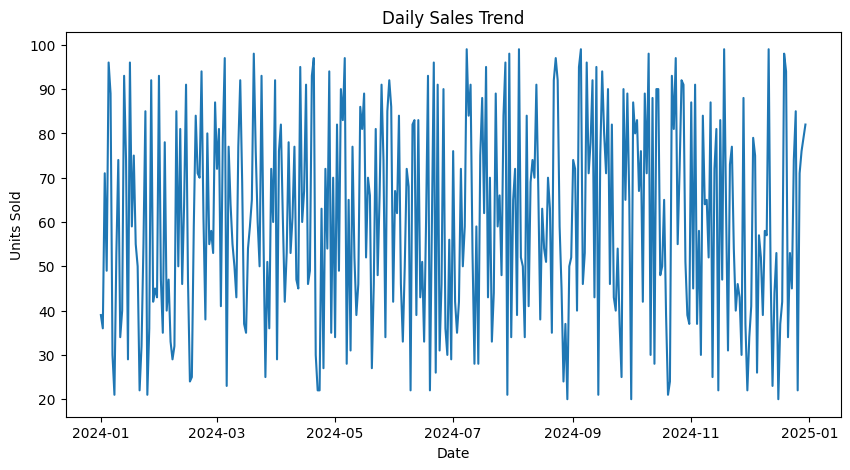

In [3]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10,5))

plt.plot(df['date'], df['qty_sold'])

plt.title('Daily Sales Trend')

plt.xlabel('Date')

plt.ylabel('Units Sold')

plt.show()

In [4]:
df['forecast'] = df['qty_sold'].rolling(7).mean()

df[['qty_sold','forecast']].tail(10)

,qty_sold,forecast
355,34,54.000000
356,53,54.000000
357,45,57.571429
358,74,62.857143
359,85,69.000000
360,22,58.142857
361,71,54.857143
362,76,60.857143
363,79,64.571429
364,82,69.857143


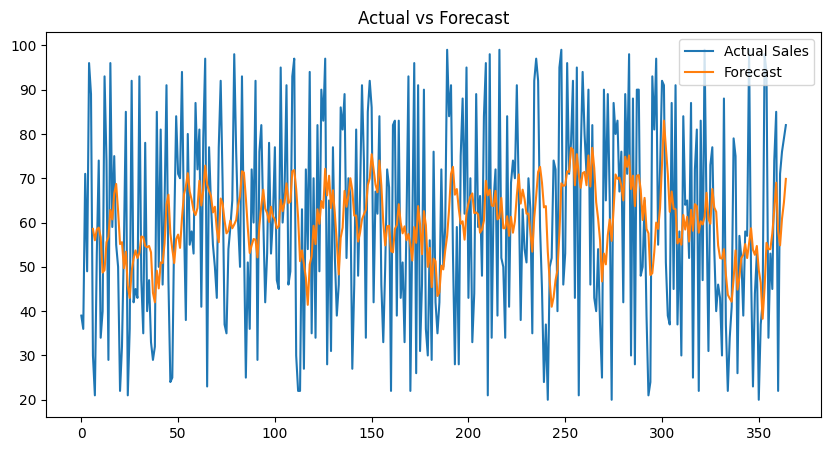

In [5]:
plt.figure(figsize=(10,5))

plt.plot(df['qty_sold'], label='Actual Sales')

plt.plot(df['forecast'], label='Forecast')

plt.legend()

plt.title('Actual vs Forecast')

plt.show()

In [6]:
forecast_avg = df['forecast'].mean()

sales_std = df['qty_sold'].std()

safety_stock = 1.65 * sales_std

print("Safety Stock =", safety_stock)

Safety Stock = 38.02265662608299


In [7]:
lead_time = 7

reorder_point = (forecast_avg * lead_time) + safety_stock

print("Reorder Point =", reorder_point)

Reorder Point = 459.83881261494093


In [8]:
current_stock = 400

order_qty = reorder_point - current_stock

results = pd.DataFrame({
'Current Stock':[current_stock],
'Safety Stock':[safety_stock],
'Reorder Point':[reorder_point],
'Recommended Order Qty':[order_qty]
})

results

,Current Stock,Safety Stock,Reorder Point,Recommended Order Qty
0,400,38.022657,459.838813,59.838813


In [9]:
results.to_csv("inventory_recommendations.csv", index=False)

print("CSV Saved Successfully")

CSV Saved Successfully


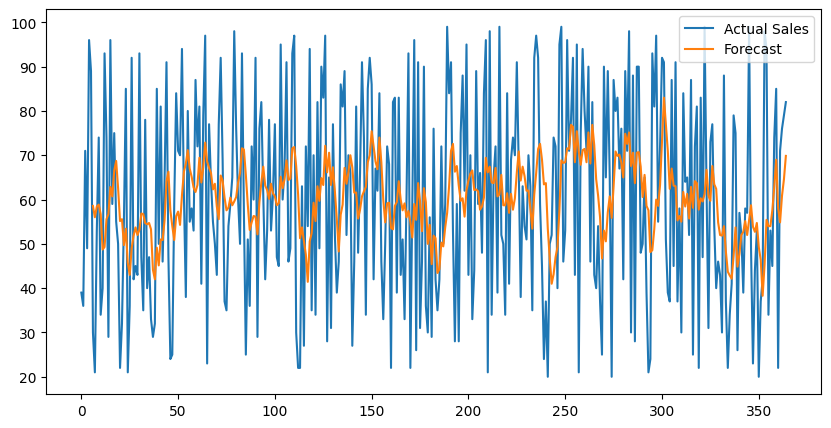

In [10]:
plt.figure(figsize=(10,5))

plt.plot(df['qty_sold'], label='Actual Sales')

plt.plot(df['forecast'], label='Forecast')

plt.legend()

plt.savefig("forecast_graph.png")

plt.show()

In [11]:
import os
print(os.getcwd())

/home/user/Desktop/Retail-Sales-Forecasting-Inventory-Optimization


In [12]:
import os
print(os.listdir())

['retail_sales_forecasting_project.ipynb', 'forecast_graph.png', '.ipynb_checkpoints', 'inventory_recommendations.csv', 'venv']


In [13]:
print(os.listdir())

['retail_sales_forecasting_project.ipynb', 'forecast_graph.png', '.ipynb_checkpoints', 'inventory_recommendations.csv', 'venv']


In [1]:
products = ['Rice','Milk','Soap']

dates = pd.date_range(start='2024-01-01', periods=365)

data = []

for product in products:
    
    sales = np.random.randint(20,100,size=365)
    
    for i in range(365):
        
        data.append([
            dates[i],
            product,
            sales[i]
        ])

multi_df = pd.DataFrame(
data,
columns=['date','product','qty_sold']
)

multi_df.head(10)

NameError: name 'pd' is not defined

In [2]:
import pandas as pd
import numpy as np

In [3]:
products = ['Rice','Milk','Soap']

dates = pd.date_range(start='2024-01-01', periods=365)

data = []

for product in products:
    
    sales = np.random.randint(20,100,size=365)
    
    for i in range(365):
        
        data.append([
            dates[i],
            product,
            sales[i]
        ])

multi_df = pd.DataFrame(
data,
columns=['date','product','qty_sold']
)

multi_df.head(10)

,date,product,qty_sold
0,2024-01-01,Rice,30
1,2024-01-02,Rice,40
2,2024-01-03,Rice,57
3,2024-01-04,Rice,74
4,2024-01-05,Rice,85
5,2024-01-06,Rice,34
6,2024-01-07,Rice,38
7,2024-01-08,Rice,44
8,2024-01-09,Rice,40
9,2024-01-10,Rice,98


In [4]:
multi_df['product'].unique()

<StringArray>
['Rice', 'Milk', 'Soap']
Length: 3, dtype: str

NameError: name 'plt' is not defined

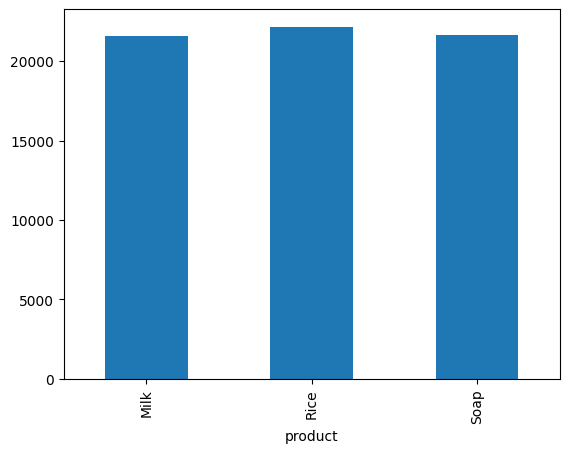

In [5]:
product_sales = multi_df.groupby('product')['qty_sold'].sum()

product_sales.plot(kind='bar')

plt.title('Product Wise Sales')

plt.show()

NameError: name 'plt' is not defined

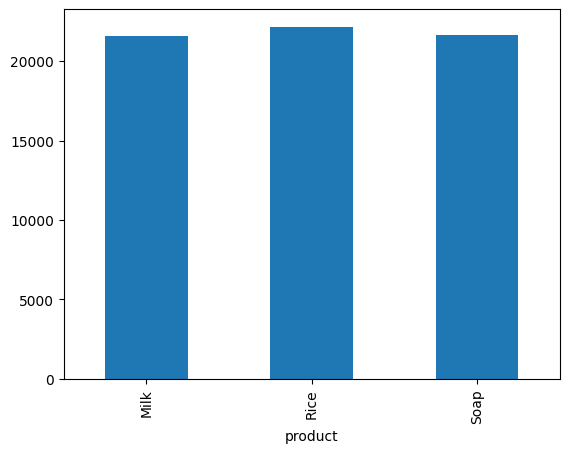

In [6]:
product_sales.plot(kind='bar')

plt.title('Product Wise Sales')

plt.savefig("product_sales_graph.png")

plt.show()

In [7]:
import matplotlib.pyplot as plt

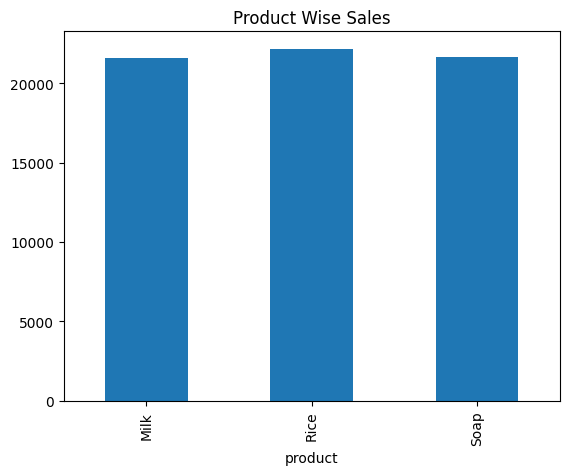

In [8]:
product_sales.plot(kind='bar')

plt.title('Product Wise Sales')

plt.savefig("product_sales_graph.png")

plt.show()

In [9]:
inventory_results = []

for product in products:
    
    product_data = multi_df[multi_df['product']==product]
    
    avg_sales = product_data['qty_sold'].mean()
    
    std_sales = product_data['qty_sold'].std()
    
    safety_stock = 1.65 * std_sales
    
    lead_time = 7
    
    reorder_point = (avg_sales*lead_time)+safety_stock
    
    current_stock = 400
    
    order_qty = reorder_point-current_stock
    
    inventory_results.append([
        product,
        safety_stock,
        reorder_point,
        order_qty
    ])

inventory_table = pd.DataFrame(
inventory_results,
columns=[
'Product',
'Safety Stock',
'Reorder Point',
'Recommended Order Qty'
])

inventory_table

,Product,Safety Stock,Reorder Point,Recommended Order Qty
0,Rice,37.883612,462.563064,62.563064
1,Milk,37.850423,451.502478,51.502478
2,Soap,37.247637,451.781884,51.781884


In [10]:
inventory_table.to_csv(
"multi_product_inventory.csv",
index=False
)

print("Multi-product inventory saved")

Multi-product inventory saved


In [11]:
import os

print(os.listdir())

['retail_sales_forecasting_project.ipynb', 'forecast_graph.png', 'multi_product_inventory.csv', '.ipynb_checkpoints', 'product_sales_graph.png', 'inventory_recommendations.csv', 'venv']


In [12]:
inventory_table['Stockout Risk'] = inventory_table[
'Recommended Order Qty'
].apply(
lambda x: 'High Risk' if x > 0 else 'Safe'
)

inventory_table

,Product,Safety Stock,Reorder Point,Recommended Order Qty,Stockout Risk
0,Rice,37.883612,462.563064,62.563064,High Risk
1,Milk,37.850423,451.502478,51.502478,High Risk
2,Soap,37.247637,451.781884,51.781884,High Risk


In [13]:
print("RETAIL INVENTORY DASHBOARD")

print("\nTotal Products:")
print(len(products))

print("\nInventory Recommendations:")
print(inventory_table)

RETAIL INVENTORY DASHBOARD

Total Products:
3

Inventory Recommendations:
  Product  Safety Stock  Reorder Point  Recommended Order Qty Stockout Risk
0    Rice     37.883612     462.563064              62.563064     High Risk
1    Milk     37.850423     451.502478              51.502478     High Risk
2    Soap     37.247637     451.781884              51.781884     High Risk


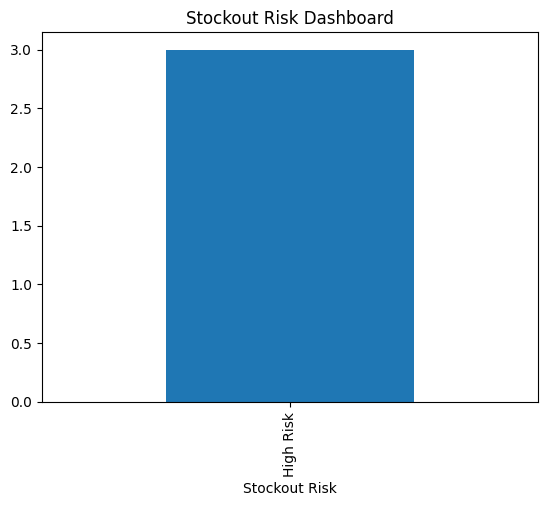

In [14]:
risk_counts = inventory_table['Stockout Risk'].value_counts()

risk_counts.plot(kind='bar')

plt.title('Stockout Risk Dashboard')

plt.show()

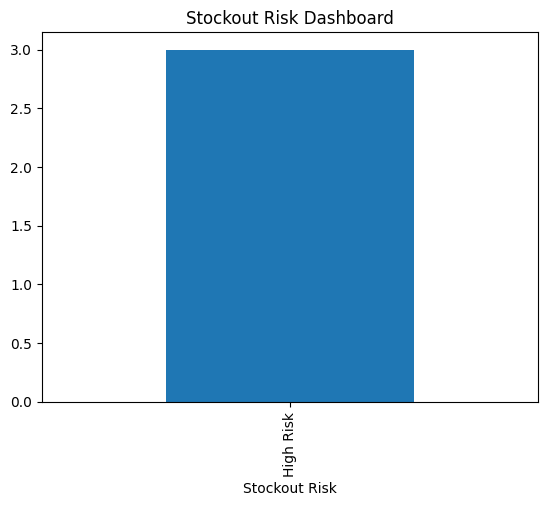

In [15]:
risk_counts.plot(kind='bar')

plt.title('Stockout Risk Dashboard')

plt.savefig("stockout_dashboard.png")

plt.show()

In [16]:
inventory_table.to_csv(
"final_inventory_dashboard_report.csv",
index=False
)

print("Final dashboard report saved")

Final dashboard report saved


In [1]:
import pandas as pd

df = pd.read_csv("final_inventory_dashboard_report.csv")
df.head()

,Product,Safety Stock,Reorder Point,Recommended Order Qty,Stockout Risk
0,Rice,37.883612,462.563064,62.563064,High Risk
1,Milk,37.850423,451.502478,51.502478,High Risk
2,Soap,37.247637,451.781884,51.781884,High Risk


In [2]:
import matplotlib.pyplot as plt

df.groupby("Product")["Sales"].sum().plot(kind="bar")
plt.title("Total Sales per Product")
plt.show()

KeyError: 'Column not found: Sales'

In [3]:
print(df.columns)

Index(['Product', 'Safety Stock', 'Reorder Point', 'Recommended Order Qty',
       'Stockout Risk'],
      dtype='str')


In [4]:
import matplotlib.pyplot as plt

df.set_index("product")[["safety stock", "reorder point"]].plot(kind="bar")

plt.title("Inventory Optimization Report")
plt.xticks(rotation=45)
plt.show()

KeyError: "None of ['product'] are in the columns"

In [5]:
print(df.head())

  Product  Safety Stock  Reorder Point  Recommended Order Qty Stockout Risk
0    Rice     37.883612     462.563064              62.563064     High Risk
1    Milk     37.850423     451.502478              51.502478     High Risk
2    Soap     37.247637     451.781884              51.781884     High Risk


In [6]:
print(df.columns.tolist())

['Product', 'Safety Stock', 'Reorder Point', 'Recommended Order Qty', 'Stockout Risk']


In [7]:
df.columns = df.columns.str.strip()
print(df.columns)

Index(['Product', 'Safety Stock', 'Reorder Point', 'Recommended Order Qty',
       'Stockout Risk'],
      dtype='str')


In [8]:
import matplotlib.pyplot as plt

df.set_index("product")[["safety stock", "reorder point"]].plot(kind="bar")

plt.title("Inventory Optimization Report")
plt.xticks(rotation=45)
plt.show()

KeyError: "None of ['product'] are in the columns"

In [9]:
print(df.columns)
print(df.head())

Index(['Product', 'Safety Stock', 'Reorder Point', 'Recommended Order Qty',
       'Stockout Risk'],
      dtype='str')
  Product  Safety Stock  Reorder Point  Recommended Order Qty Stockout Risk
0    Rice     37.883612     462.563064              62.563064     High Risk
1    Milk     37.850423     451.502478              51.502478     High Risk
2    Soap     37.247637     451.781884              51.781884     High Risk


In [10]:
df.columns = df.columns.str.strip()
print(df.columns)

Index(['Product', 'Safety Stock', 'Reorder Point', 'Recommended Order Qty',
       'Stockout Risk'],
      dtype='str')


In [11]:
import matplotlib.pyplot as plt

df.set_index("product")[["safety stock", "reorder point"]].plot(kind="bar")

plt.title("Inventory Optimization Report")
plt.xticks(rotation=45)
plt.show()

KeyError: "None of ['product'] are in the columns"

In [12]:
for col in df.columns:
    print(repr(col))

'Product'
'Safety Stock'
'Reorder Point'
'Recommended Order Qty'
'Stockout Risk'


In [13]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10,5))

plt.bar(df["product"], df["safety stock"], label="Safety Stock")
plt.bar(df["product"], df["reorder point"], label="Reorder Point", alpha=0.6)

plt.xticks(rotation=45)
plt.legend()
plt.title("Inventory Optimization Report")

plt.show()

KeyError: 'product'

<Figure size 1000x500 with 0 Axes>

In [14]:
print(df.columns.tolist())

['Product', 'Safety Stock', 'Reorder Point', 'Recommended Order Qty', 'Stockout Risk']


In [15]:
df.columns = df.columns.str.strip()
df = df.reset_index()
print(df.columns)

Index(['index', 'Product', 'Safety Stock', 'Reorder Point',
       'Recommended Order Qty', 'Stockout Risk'],
      dtype='str')


In [16]:
print(df.head())

   index Product  Safety Stock  Reorder Point  Recommended Order Qty  \
0      0    Rice     37.883612     462.563064              62.563064   
1      1    Milk     37.850423     451.502478              51.502478   
2      2    Soap     37.247637     451.781884              51.781884   

  Stockout Risk  
0     High Risk  
1     High Risk  
2     High Risk  


In [17]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10,5))

plt.bar(df["product"], df["safety stock"], label="Safety Stock")
plt.bar(df["product"], df["reorder point"], label="Reorder Point", alpha=0.6)

plt.xticks(rotation=45)
plt.legend()
plt.title("Inventory Optimization Report")

plt.show()

KeyError: 'product'

<Figure size 1000x500 with 0 Axes>

In [18]:
print(df.columns.tolist())

['index', 'Product', 'Safety Stock', 'Reorder Point', 'Recommended Order Qty', 'Stockout Risk']


In [19]:
df.columns = df.columns.str.strip()
print(df.columns.tolist())

['index', 'Product', 'Safety Stock', 'Reorder Point', 'Recommended Order Qty', 'Stockout Risk']


In [20]:
print(df.head())

   index Product  Safety Stock  Reorder Point  Recommended Order Qty  \
0      0    Rice     37.883612     462.563064              62.563064   
1      1    Milk     37.850423     451.502478              51.502478   
2      2    Soap     37.247637     451.781884              51.781884   

  Stockout Risk  
0     High Risk  
1     High Risk  
2     High Risk  


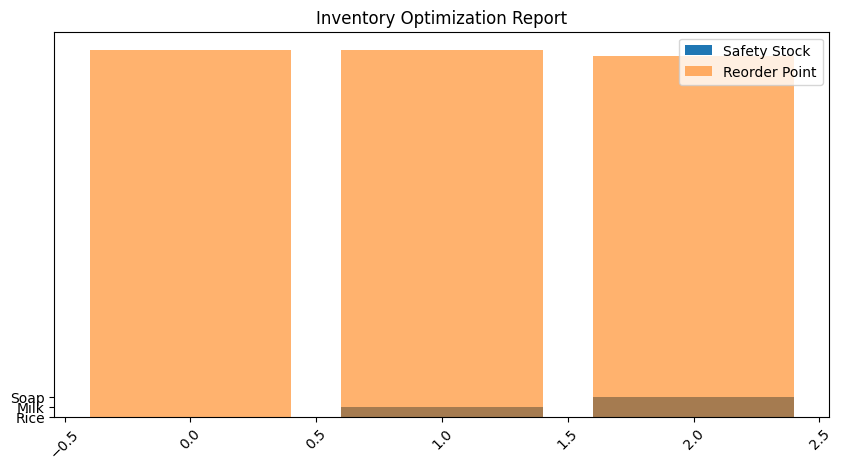

In [21]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10,5))

plt.bar(df.iloc[:,0], df.iloc[:,1], label="Safety Stock")
plt.bar(df.iloc[:,0], df.iloc[:,2], label="Reorder Point", alpha=0.6)

plt.xticks(rotation=45)
plt.legend()
plt.title("Inventory Optimization Report")

plt.show()

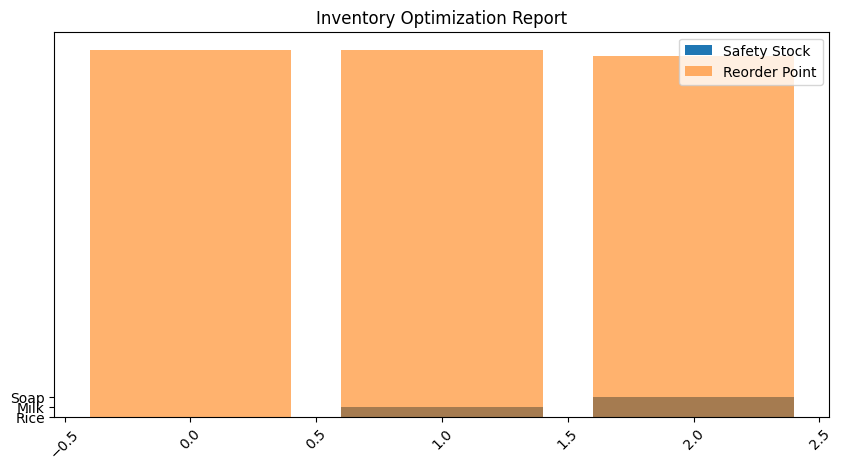

<Figure size 640x480 with 0 Axes>

In [22]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10,5))

plt.bar(df.iloc[:,0], df.iloc[:,1], label="Safety Stock")
plt.bar(df.iloc[:,0], df.iloc[:,2], label="Reorder Point", alpha=0.6)

plt.xticks(rotation=45)
plt.legend()
plt.title("Inventory Optimization Report")

plt.show()
plt.savefig("inventory_optimization_graph.png", bbox_inches="tight")

In [23]:
df.head()

,index,Product,Safety Stock,Reorder Point,Recommended Order Qty,Stockout Risk
0,0,Rice,37.883612,462.563064,62.563064,High Risk
1,1,Milk,37.850423,451.502478,51.502478,High Risk
2,2,Soap,37.247637,451.781884,51.781884,High Risk


In [24]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
import matplotlib.pyplot as plt

In [25]:
df["time_index"] = np.arange(len(df))

In [26]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [27]:
df["time_index"] = np.arange(len(df))
df.head()

,index,Product,Safety Stock,Reorder Point,Recommended Order Qty,Stockout Risk,time_index
0,0,Rice,37.883612,462.563064,62.563064,High Risk,0
1,1,Milk,37.850423,451.502478,51.502478,High Risk,1
2,2,Soap,37.247637,451.781884,51.781884,High Risk,2


In [28]:
from sklearn.linear_model import LinearRegression

X = df[["time_index"]]
y = df["reorder point"]

model = LinearRegression()
model.fit(X, y)

KeyError: 'reorder point'

In [29]:
print(df.columns.tolist())

['index', 'Product', 'Safety Stock', 'Reorder Point', 'Recommended Order Qty', 'Stockout Risk', 'time_index']


In [30]:
df.head()

,index,Product,Safety Stock,Reorder Point,Recommended Order Qty,Stockout Risk,time_index
0,0,Rice,37.883612,462.563064,62.563064,High Risk,0
1,1,Milk,37.850423,451.502478,51.502478,High Risk,1
2,2,Soap,37.247637,451.781884,51.781884,High Risk,2


In [31]:
y = df["reorder point"]

KeyError: 'reorder point'

In [32]:
y = df.iloc[:,2]   # third column

In [33]:
print(df.columns.tolist())

['index', 'Product', 'Safety Stock', 'Reorder Point', 'Recommended Order Qty', 'Stockout Risk', 'time_index']


In [34]:
X = df[["time_index"]]
y = df["Reorder Point"]

In [35]:
from sklearn.linear_model import LinearRegression

model = LinearRegression()
model.fit(X, y)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies a different convergence criterion for the `lsqr` solver.`tol` is set as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. This parameter has no effect when fittingon dense data... versionadded:: 1.7",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary ` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False


In [36]:
import numpy as np

future = np.arange(len(df), len(df)+10).reshape(-1,1)
forecast = model.predict(future)

/home/user/Desktop/Retail-Sales-Forecasting-Inventory-Optimization/venv/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


In [37]:
future_df = pd.DataFrame({"time_index": np.arange(len(df), len(df)+10)})

forecast = model.predict(future_df)

In [38]:
import numpy as np
import pandas as pd

future_df = pd.DataFrame({
    "time_index": np.arange(len(df), len(df)+10)
})

forecast = model.predict(future_df)
print(forecast)

[444.50129555 439.11070572 433.72011589 428.32952606 422.93893623
 417.54834639 412.15775656 406.76716673 401.3765769  395.98598707]


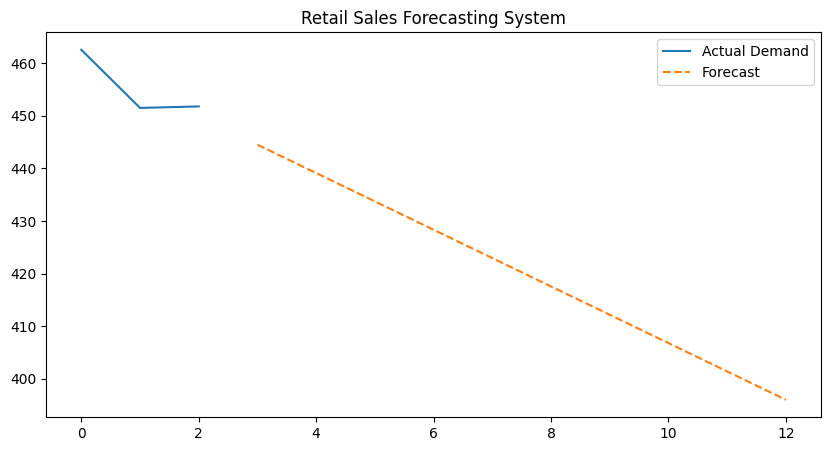

In [39]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10,5))

plt.plot(df["time_index"], df["Reorder Point"], label="Actual Demand")
plt.plot(
    np.arange(len(df), len(df)+10),
    forecast,
    label="Forecast",
    linestyle="dashed"
)

plt.title("Retail Sales Forecasting System")
plt.legend()
plt.show()

In [1]:
df_forecast = pd.DataFrame({
    "Future_Time": np.arange(len(df), len(df)+10),
    "Forecasted_Demand": forecast
})

df_forecast.to_csv("forecast_output.csv", index=False)

print("Forecast saved successfully")

NameError: name 'pd' is not defined

In [2]:
import pandas as pd
import numpy as np

In [3]:
df_forecast = pd.DataFrame({
    "Future_Time": np.arange(len(df), len(df)+10),
    "Forecasted_Demand": forecast
})

df_forecast.to_csv("forecast_output.csv", index=False)

print("Forecast saved successfully")

NameError: name 'df' is not defined

In [4]:
import pandas as pd
import numpy as np

df = pd.read_csv("final_inventory_dashboard_report.csv")

df.head()

,Product,Safety Stock,Reorder Point,Recommended Order Qty,Stockout Risk
0,Rice,37.883612,462.563064,62.563064,High Risk
1,Milk,37.850423,451.502478,51.502478,High Risk
2,Soap,37.247637,451.781884,51.781884,High Risk


In [5]:
import os
print(os.listdir())

['retail_sales_forecasting_project.ipynb', 'forecast_graph.png', 'multi_product_inventory.csv', '.ipynb_checkpoints', 'product_sales_graph.png', 'inventory_recommendations.csv', 'venv', 'stockout_dashboard.png', 'final_inventory_dashboard_report.csv', 'inventory_optimization_graph.png']


In [6]:
df["time_index"] = np.arange(len(df))

In [7]:
from sklearn.linear_model import LinearRegression

X = df[["time_index"]]
y = df["Reorder Point"]

model = LinearRegression()
model.fit(X, y)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies a different convergence criterion for the `lsqr` solver.`tol` is set as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. This parameter has no effect when fittingon dense data... versionadded:: 1.7",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary ` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False


In [8]:
future = np.arange(len(df), len(df)+10).reshape(-1,1)
forecast = model.predict(future)

/home/user/Desktop/Retail-Sales-Forecasting-Inventory-Optimization/venv/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


In [9]:
future_df = pd.DataFrame({
    "time_index": np.arange(len(df), len(df)+10)
})

forecast = model.predict(future_df)

In [10]:
df_forecast = pd.DataFrame({
    "Future_Time": np.arange(len(df), len(df)+10),
    "Forecasted_Demand": forecast
})

df_forecast.to_csv("forecast_output.csv", index=False)

print("Forecast saved successfully")

Forecast saved successfully


In [11]:
inventory_summary = df[[
    "Product",
    "Safety Stock",
    "Reorder Point",
    "Recommended Order Qty",
    "Stockout Risk"
]]

inventory_summary.to_csv("final_inventory_report.csv", index=False)

inventory_summary.head()

,Product,Safety Stock,Reorder Point,Recommended Order Qty,Stockout Risk
0,Rice,37.883612,462.563064,62.563064,High Risk
1,Milk,37.850423,451.502478,51.502478,High Risk
2,Soap,37.247637,451.781884,51.781884,High Risk


In [12]:
import joblib

joblib.dump(model, "forecast_model.pkl")

print("Model saved successfully")

Model saved successfully
